### Buschfeuer – Lösung Schritt für Schritt

*32. Bundeswettbewerb Informatik (2013/2014), 2. Runde, Aufgabe 1*

Es brennt in den Pontypandy Mountains, und das Feuer breitet sich rasend schnell aus. Leider sind die Berge nicht per
Kraftfahrzeug erreichbar, so dass der Löschhubschrauber der Mountain Rangers verwendet werden muss. Der Hubschrauber kann genug
Wasser aufnehmen, um genau ein brennendes Waldstück vollständig zu löschen. Ein gelöschtes Waldstück kann nicht mehr brennen.

Deine Aufgabe ist es, den Löscheinsatz des Hubschraubers so zu steuern, dass möglichst wenig Waldstücke in Brand geraten.

Glücklicherweise existieren Brandschneisen im Wald, so dass sich das Feuer nicht beliebig ausbreiten kann. Das gesamte Gebiet kann
durch ein Raster modelliert werden, in dem jedes Feld einem Waldstück oder einem Stück einer Brandschneise entspricht. Das Feuer
kann sich von einem Feld in einer Stunde auf die vier benachbarten Felder ausbreiten. Für die Aufnahme und den Transport des
Wassers benötigt der Hubschrauber ebenfalls eine Stunde.

Die Abbildung zeigt den Verlauf einer Löschaktion. Weiße Felder stellen Stücke von Brandschneisen dar, rote (dunkle) Felder in
Brand geratene Waldstücke. Das Symbol zeigt, welche Waldstücke gelöscht wurden.

*(Bild im Aufgabenblatt: sieben Raster mit 10 × 10 Feldern, grün Wald, weiß Brandschneise, rot Feuer. Im ersten Raster brennt ein
Feld in der Mitte, in jedem weiteren hat sich das Feuer eine Stunde lang ausgebreitet und ein Feld mehr ist gelöscht. In Schritt 3
zeichnen wir den ganzen Verlauf nach.)*

#### Aufgabe

Wo muss der Hubschrauber wann Wasser abwerfen, damit möglichst wenige Waldstücke in Brand geraten? Schreibe ein Programm, das diese
Frage für gegebene Raster mit Waldstücken, Brandschneisen und einem oder mehreren Brandherden beantworten kann.

Feuerwehrfrau Sheila fragt sich, ob mehr Wald gerettet werden kann, wenn wahlweise auch nicht brennende Waldstücke mit Wasser vor dem
Feuer geschützt werden. Was meinst du?

#### Beispieldaten

Zu dieser Aufgabe gibt es keine Beispieldaten. Die Karte aus dem Aufgabenblatt haben wir aus dem Bild abgelesen und in
`beispieldaten/aufgabenblatt.txt` gespeichert, den Feuerring aus Abbildung 1 der Lösungshinweise in `beispieldaten/feuerring.txt`.
Jede Zeile der Datei ist eine Zeile des Rasters: `.` ist Wald, `#` Brandschneise und `F` ein Brandherd. In `eigene_testdaten/`
liegen drei weitere Karten: `klein.txt` (6 × 6), `zwei_herde.txt` (15 × 15 mit zwei Brandherden) und `drei_herde.txt` (20 × 20 mit
drei Brandherden); die beiden großen haben wir mit Zufallszahlen erzeugt.

## Was dir bei dieser Aufgabe hilft

**Algorithmische Kenntnisse**
- **Simulation auf einem Raster:** Jedes Feld ist ein Tupel `(zeile, spalte)`. Wald und Feuer speichern wir als **Mengen** solcher
  Tupel. Ein Feuer-Zug ist dann nur noch: Sammle alle Waldfelder, die neben einem Feuerfeld liegen.
- **Gierige Verfahren (Greedy):** In jeder Stunde das tun, was *sofort* am meisten hilft. Das ist schnell, aber nicht immer am besten.
- **Vollständige Suche mit Rekursion (Backtracking):** Jede Stunde hat der Hubschrauber ein paar sinnvolle Möglichkeiten. Eine
  Funktion probiert jede davon aus und ruft sich für die nächste Stunde selbst wieder auf. So entsteht ein *Spielbaum* mit allen
  Löschplänen.
- **Branch and Bound („Verzweigen und Beschränken“):** Wir merken uns das beste Ergebnis, das wir schon kennen. Kann ein Ast des
  Baums nach einer einfachen Abschätzung (der *Schranke*) nicht mehr besser werden, brechen wir ihn sofort ab.
- **Zustände merken:** Kommt die Suche auf verschiedenen Wegen zur gleichen Lage, muss sie diese nur einmal untersuchen.

**Nützliche Funktionen und Bibliotheken**
- Mengen: `a | b` (Vereinigung), `a - b` (Differenz), `x in a` (schnell, auch bei großen Mengen). `a - {x}` ist eine neue Menge
  ohne `x`; die alte Menge bleibt unverändert. Das ist bei der Rekursion wichtig.
- `frozenset(a)` ist eine unveränderliche Menge. Anders als `set` darf sie Schlüssel eines Dictionarys sein.
- Listen von Tupeln sortiert `sort()` nach dem ersten Eintrag, bei Gleichstand nach dem zweiten usw.
- `matplotlib` mit `imshow` malt ein Raster aus Zahlen als farbige Kästchen.

## Die Idee in Worten

Die Lösungshinweise beschreiben den Einsatz als **Spiel mit zwei Gegnern**, die abwechselnd ziehen:

1. Die Karte mit Wald, Brandschneisen und Feuer ist gegeben.
2. **Feuer-Zug:** Alle Waldfelder, die links, rechts, oben oder unten an ein Feuerfeld grenzen, werden zu Feuerfeldern.
3. Grenzt kein Waldfeld mehr an ein Feuerfeld, ist das Spiel zu Ende.
4. **Lösch-Zug:** Der Hubschrauber löscht ein Feuerfeld (bei Sheilas Frage auch ein Waldfeld). Es kann nie wieder brennen.
5. Weiter mit Schritt 2.

Das Feuer zieht also zuerst: Im Bild des Aufgabenblatts hat sich das Feuer im zweiten Raster schon ausgebreitet, bevor das erste
Feld gelöscht ist. Ein gelöschtes Feld zählt wie ein verbranntes nicht mehr als Wald.

**Bewertung.** Am Ende zählen wir `W` = Anzahl der übrigen Waldfelder und `G` = Anzahl der gelöschten Felder. Ein Ergebnis ist
besser, wenn `W` größer ist, bei gleichem `W`, wenn `G` kleiner ist (weniger Wasser). Wie die Hinweise schreiben wir kurz `(W, G)`.

**Welche Felder lohnen sich?** Ein Feuerfeld, das nur noch an Feuer, Schneisen oder Gelöschtes grenzt, kann nichts mehr anzünden;
es zu löschen ist verschwendet (die Hinweise nennen das *Inferno-Kriterium*). Sinnvoll sind also nur die Feuerfelder mit einem
Waldnachbarn, wir nennen sie die **Feuerfront**. Dazu kommt „nichts tun“: Es spart Wasser, wenn Löschen nichts mehr bringt. Und
besteht die Front nur aus einem Feld, löschen wir genau dieses, denn dann ist das Feuer aus (*Endzug-Kriterium*).

**Plan.** Zuerst simulieren wir das Spiel für einen gegebenen Löschplan und prüfen damit den Plan des Aufgabenblatts. Dann ein
gieriges Verfahren und schließlich eine vollständige Suche mit Schranke, die beweisbar den besten Plan findet.

## Schritt 1: Die Karte einlesen

Wir lesen die Datei Zeile für Zeile und lassen leere Zeilen weg.

In [ ]:
def lies_karte(dateiname):
    """Liest eine Karte: '.' Wald, '#' Brandschneise, 'F' Feuer. Ergebnis: Liste von Zeichenketten."""
    karte = []
    with open(dateiname) as datei:
        for zeile in datei:
            zeile = zeile.strip()
            if zeile != '':
                karte.append(zeile)
    return karte


blatt = lies_karte('beispieldaten/aufgabenblatt.txt')
for zeile in blatt:
    print(zeile)
print(len(blatt), 'Zeilen,', len(blatt[0]), 'Spalten')

..#.....#.
.##......#
..........
..###.###.
.....F....
..##......
....#..#..
#...#..#.#
.#..#..#..
..........
10 Zeilen, 10 Spalten


Für die Rechnung brauchen wir die Felder als Mengen. Ein Feld ist ein Tupel `(zeile, spalte)`, gezählt ab 0 von links oben.

In [ ]:
def felder(karte):
    """Menge der Waldfelder und Menge der Feuerfelder einer Karte."""
    wald = set()
    feuer = set()
    for z in range(len(karte)):
        for s in range(len(karte[z])):
            if karte[z][s] == '.':
                wald.add((z, s))
            elif karte[z][s] == 'F':
                feuer.add((z, s))
    return wald, feuer


wald, feuer = felder(blatt)
print('Wald:', len(wald), 'Feuer:', feuer)

Wald: 77 Feuer: {(4, 5)}


## Schritt 2: Nachbarn und Feuer-Zug

Die vier Nachbarn eines Feldes liegen eine Zeile oder eine Spalte daneben. Felder außerhalb der Karte müssen wir nicht
aussortieren: Sie sind nie in der Menge `wald`, und nur nach dieser Menge fragen wir.

Beim Feuer-Zug sammeln wir zuerst alle neuen Feuerfelder und ändern erst danach die Mengen. Sonst würde ein Feld, das gerade Feuer
gefangen hat, in derselben Stunde schon seine Nachbarn anzünden.

In [ ]:
def nachbarn(feld):
    """Die vier Nachbarn eines Feldes (auch solche außerhalb der Karte)."""
    z, s = feld
    return [(z - 1, s), (z + 1, s), (z, s - 1), (z, s + 1)]


def feuer_zug(wald, feuer):
    """Alle Waldfelder neben einem Feuerfeld fangen Feuer. Gibt neue Mengen (wald, feuer) zurück."""
    neu = set()
    for feld in feuer:
        for n in nachbarn(feld):
            if n in wald:
                neu.add(n)
    return wald - neu, feuer | neu


def feuerfront(wald, feuer):
    """Die Feuerfelder, die noch mindestens ein Waldfeld neben sich haben."""
    front = set()
    for feld in feuer:
        for n in nachbarn(feld):
            if n in wald:
                front.add(feld)
    return front

Zum Anschauen schreiben wir eine Lage als Text: `.` Wald, `#` Schneise, `F` Feuer. Gelöschte Felder bekommen die Nummer der Stunde,
in der sie gelöscht wurden (ab 10 Buchstaben). Dafür steht in `geloescht` zu jedem gelöschten Feld die Stunde.

In [ ]:
ZEICHEN = '123456789abcdefghijklmnopqrstuvwxyz'


def als_text(karte, wald, feuer, geloescht):
    zeilen = []
    for z in range(len(karte)):
        zeile = ''
        for s in range(len(karte[z])):
            if (z, s) in geloescht:
                zeile += ZEICHEN[geloescht[(z, s)] - 1]
            elif (z, s) in feuer:
                zeile += 'F'
            elif (z, s) in wald:
                zeile += '.'
            else:
                zeile += '#'
        zeilen.append(zeile)
    return zeilen


wald, feuer = felder(blatt)
wald1, feuer1 = feuer_zug(wald, feuer)
for zeile in als_text(blatt, wald1, feuer1, {}):
    print(zeile)
print('Feuerfront:', sorted(feuerfront(wald1, feuer1)))

..#.....#.
.##......#
..........
..###F###.
....FFF...
..##.F....
....#..#..
#...#..#.#
.#..#..#..
..........
Feuerfront: [(3, 5), (4, 4), (4, 6), (5, 5)]


Nach dem ersten Feuer-Zug brennen fünf Felder. Das mittlere hat keinen Waldnachbarn mehr und gehört nicht zur Front; nur die vier
anderen lohnen sich zum Löschen.

## Schritt 3: Ein Löscheinsatz nach Plan

Ein **Plan** ist eine Liste: Eintrag Nummer k sagt, welches Feld der Hubschrauber in Stunde k löscht (`None` heißt: nichts tun).
`spiele` führt das Spiel nach den Regeln aus und merkt sich nach jedem Lösch-Zug die Lage. Ist der Plan zu Ende, das Feuer aber
nicht, tut der Hubschrauber nichts mehr. Ein Feld, das nicht gelöscht werden darf, meldet die Funktion als Fehler; Waldfelder sind
nur mit `giessen=True` erlaubt (für Sheilas Frage).

In [ ]:
def spiele(karte, plan, giessen=False):
    """Spielt den Löscheinsatz durch. Ergebnis: Liste der Lagen (wald, feuer, geloescht), erst die Startlage,
    dann die Lage nach jedem Lösch-Zug und, falls sie sich danach noch ändert, die Endlage."""
    wald, feuer = felder(karte)
    geloescht = {}
    verlauf = [(wald, feuer, {})]
    wald, feuer = feuer_zug(wald, feuer)              # das Feuer zieht zuerst
    stunde = 0
    while len(feuerfront(wald, feuer)) > 0:
        feld = None
        if stunde < len(plan):
            feld = plan[stunde]
        stunde += 1
        if feld is not None:
            if feld in feuer:
                feuer = feuer - {feld}
            elif giessen and feld in wald:
                wald = wald - {feld}
            else:
                raise ValueError(f'Feld {feld} darf in Stunde {stunde} nicht gelöscht werden')
            geloescht[feld] = stunde
        verlauf.append((wald, feuer, dict(geloescht)))
        wald, feuer = feuer_zug(wald, feuer)
    if wald != verlauf[-1][0]:
        verlauf.append((wald, feuer, dict(geloescht)))
    return verlauf


def bewertung(verlauf):
    """(W, G) der Endlage."""
    wald, feuer, geloescht = verlauf[-1]
    return (len(wald), len(geloescht))

Den Plan des Aufgabenblatts lesen wir aus dem Bild ab: In den Rastern 2 bis 7 kommt jeweils ein gelöschtes Feld dazu.

In [ ]:
plan_blatt = [(3, 5), (6, 5), (6, 6), (4, 1), (6, 8), (2, 9)]
verlauf_blatt = spiele(blatt, plan_blatt)
print('Lagen:', len(verlauf_blatt))
print('Ergebnis (W, G):', bewertung(verlauf_blatt))
for zeile in als_text(blatt, *verlauf_blatt[-1]):
    print(zeile)

Lagen: 7
Ergebnis (W, G): (56, 6)
..#.....#.
.##......#
.........6
..###1###F
.4FFFFFFFF
..##FFFFFF
....#23#5F
#...#..#.#
.#..#..#..
..........


Mit `*verlauf_blatt[-1]` packen wir das Tupel `(wald, feuer, geloescht)` aus, als hätten wir die drei Einträge einzeln übergeben.

Das Ergebnis `(56, 6)` steht genauso in den Lösungshinweisen (Abbildung 3a). Damit stimmen unsere Spielregeln mit denen des
Aufgabenblatts überein. Noch schöner sieht man den Verlauf als Bild, wir zeichnen ihn wie auf dem Aufgabenblatt (blau = gelöscht,
mit der Stunde).

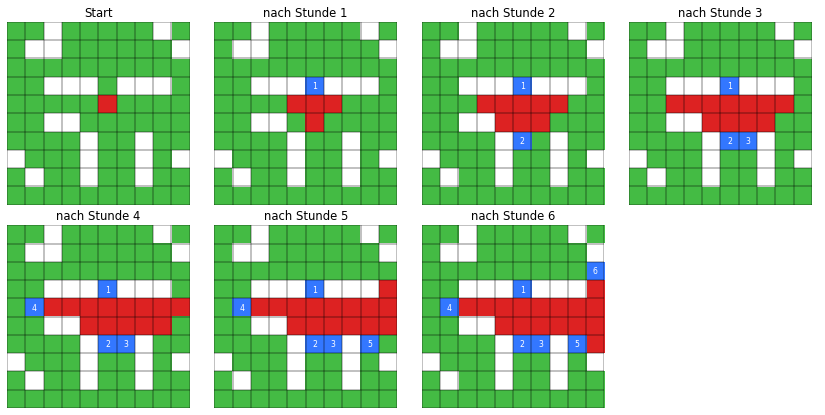

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

FARBEN = ListedColormap(['white', '#44bb44', '#dd2222', '#3377ff'])   # Schneise, Wald, Feuer, gelöscht


def male(karte, lagen, titel, spalten=4, zoll=3):
    """Zeichnet mehrere Lagen (wald, feuer, geloescht) nebeneinander, jede etwa zoll Zoll groß."""
    reihen = (len(lagen) + spalten - 1) // spalten
    fig, achsen = plt.subplots(reihen, spalten, figsize=(zoll * spalten, zoll * reihen), squeeze=False)
    for i in range(reihen * spalten):
        ax = achsen[i // spalten][i % spalten]
        ax.axis('off')
        if i >= len(lagen):
            continue
        wald, feuer, geloescht = lagen[i]
        werte = []
        for z in range(len(karte)):
            reihe = []
            for s in range(len(karte[z])):
                if (z, s) in geloescht:
                    reihe.append(3)
                elif (z, s) in feuer:
                    reihe.append(2)
                elif (z, s) in wald:
                    reihe.append(1)
                else:
                    reihe.append(0)
            werte.append(reihe)
        ax.imshow(werte, cmap=FARBEN, vmin=0, vmax=3)
        for s in range(len(karte[0]) + 1):
            ax.axvline(s - 0.5, color='black', linewidth=0.5)
        for z in range(len(karte) + 1):
            ax.axhline(z - 0.5, color='black', linewidth=0.5)
        for feld in geloescht:
            ax.text(feld[1], feld[0], str(geloescht[feld]), ha='center', va='center', color='white', fontsize=8)
        ax.set_title(titel[i])
    plt.tight_layout()
    plt.show()


titel_blatt = ['Start']
for k in range(1, len(verlauf_blatt)):
    titel_blatt.append(f'nach Stunde {k}')
male(blatt, verlauf_blatt, titel_blatt)

Das sind genau die sieben Raster des Aufgabenblatts. Nach Stunde 6 grenzt kein Waldfeld mehr an Feuer, das Spiel ist zu Ende.

## Schritt 4: Gierig löschen

Eine naheliegende Strategie: In jeder Stunde probieren wir jedes Feld der Feuerfront aus und löschen das, bei dem im **nächsten**
Feuer-Zug am wenigsten Wald verbrennt. Bei Gleichstand nehmen wir das erste Feld in der sortierten Reihenfolge.

In [ ]:
def gierig(karte):
    """Löschplan: immer das Frontfeld, nach dessen Löschen im nächsten Feuer-Zug am wenigsten verbrennt."""
    wald, feuer = felder(karte)
    wald, feuer = feuer_zug(wald, feuer)
    plan = []
    while len(feuerfront(wald, feuer)) > 0:
        bestes = None
        wenigste = None
        for feld in sorted(feuerfront(wald, feuer)):
            wald2, feuer2 = feuer_zug(wald, feuer - {feld})
            verbrannt = len(wald) - len(wald2)
            if wenigste is None or verbrannt < wenigste:
                bestes = feld
                wenigste = verbrannt
        plan.append(bestes)
        feuer = feuer - {bestes}
        wald, feuer = feuer_zug(wald, feuer)
    return plan


plan_gierig = gierig(blatt)
print('Plan:', plan_gierig)
print('Ergebnis (W, G):', bewertung(spiele(blatt, plan_gierig)))

Plan: [(3, 5), (4, 3), (4, 8), (5, 8), (9, 5), (9, 6)]
Ergebnis (W, G): (58, 6)


Gierig retten wir 58 Waldfelder, zwei mehr als der Plan des Aufgabenblatts. Ob das schon das Beste ist, wissen wir aber nicht. Dass
gierig nicht immer reicht, zeigt die kleine Karte `klein.txt`:

In [ ]:
klein = lies_karte('eigene_testdaten/klein.txt')
verlauf_klein_gierig = spiele(klein, gierig(klein))
print('gierig (W, G):', bewertung(verlauf_klein_gierig))
for zeile in als_text(klein, *verlauf_klein_gierig[-1]):
    print(zeile)

gierig (W, G): (11, 4)
..#...
..12..
.#FF#.
3FFFF4
FF#FFF
FFFFF#


Gierig schaut nur eine Stunde voraus. Es sperrt zuerst den Weg nach oben (Stunde 1 und 2) und verliert dann die größere untere
Hälfte der Karte. In Schritt 5 sehen wir: Wer den Weg nach unten sperrt, wo mehr Wald steht, und dafür den oberen Teil aufgibt,
rettet 16 statt 11 Waldfelder.

## Schritt 5: Alle Möglichkeiten durchprobieren

Jetzt suchen wir den **besten** Plan. Die Funktion `suche` bekommt eine Lage direkt nach einem Feuer-Zug:

1. Ist die Feuerfront leer, ist das Spiel aus. Ist das Ergebnis besser als das beste bisher, merken wir es uns.
2. Sonst probieren wir jedes Feld der Front (und „nichts tun“) aus: löschen, Feuer-Zug, und für die neue Lage ruft `suche` sich
   selbst auf.

Alles, was die Suche sich merken muss (bestes Ergebnis, Plan, Zähler), steht in einem Dictionary `stand`, das jeder Aufruf
weiterreicht. Der Zähler `zustaende` zählt die Aufrufe, also die untersuchten Lagen.

Das allein wäre viel zu langsam: Schon beim Aufgabenblatt gibt es in jeder Stunde mehrere Möglichkeiten, über viele Stunden. Deshalb
zwei Verbesserungen:

**Schranke.** Im nächsten Feuer-Zug verbrennt jedes *bedrohte* Waldfeld (eines neben der Front), außer den Feldern, deren einziger
brennender Nachbar das Feld ist, das wir löschen. Wir zählen für jedes Frontfeld, wie viele Waldfelder es so retten würde
(`rettet`). Mehr als

`hoechstens = len(wald) - len(bedroht) + max(rettet)`

Waldfelder können am Ende nicht übrig bleiben, egal was wir später tun. Ist das weniger als das beste bekannte `W`, brechen wir ab.
Damit die Schranke früh greift, probieren wir die Frontfelder mit großem `rettet` zuerst; so findet die Suche schnell einen guten
Plan.

**Zustände merken.** Die Zukunft hängt nur vom übrigen Wald und von der Feuerfront ab. Erreicht die Suche dieselbe Lage noch einmal
mit mindestens so vielen gelöschten Feldern, kann es von dort nicht besser werden. Als Schlüssel im Dictionary `gesehen` nehmen
wir das Paar `(frozenset(wald), frozenset(front))`.

Brennende Felder ohne Waldnachbarn spielen für die Zukunft keine Rolle mehr; deshalb gibt `suche` beim Feuer-Zug nur die Front
weiter.

In [ ]:
def besser(a, b):
    """Ist das Ergebnis a = (W, G) besser als b?"""
    return a[0] > b[0] or (a[0] == b[0] and a[1] < b[1])


def wald_am_feuer(wald, bedroht):
    """Alle Waldfelder, die über Wald mit einem bedrohten Feld verbunden sind (nur für Sheilas Frage)."""
    erreichbar = set(bedroht)
    stapel = list(bedroht)
    while len(stapel) > 0:
        feld = stapel.pop()
        for n in nachbarn(feld):
            if n in wald and n not in erreichbar:
                erreichbar.add(n)
                stapel.append(n)
    return erreichbar


def suche(wald, feuer, anzahl_geloescht, plan, stand):
    stand['zustaende'] += 1
    front = feuerfront(wald, feuer)
    if len(front) == 0:                               # Spiel zu Ende
        ergebnis = (len(wald), anzahl_geloescht)
        if besser(ergebnis, stand['beste']):
            stand['beste'] = ergebnis
            stand['plan'] = plan
        return

    # bedroht: Waldfeld -> Anzahl der Frontfelder daneben
    bedroht = {}
    for f in front:
        for n in nachbarn(f):
            if n in wald:
                bedroht[n] = bedroht.get(n, 0) + 1
    # rettet: Frontfeld -> so viele Waldfelder verschont der nächste Feuer-Zug, wenn wir dieses Feld löschen
    rettet = {}
    for f in front:
        rettet[f] = 0
        for n in nachbarn(f):
            if n in wald and bedroht[n] == 1:
                rettet[f] += 1

    if stand['schranke']:
        hoechstens = len(wald) - len(bedroht) + max(rettet.values())
        if hoechstens < stand['beste'][0]:
            return
    if stand['merken']:
        schluessel = (frozenset(wald), frozenset(front))
        if schluessel in stand['gesehen'] and stand['gesehen'][schluessel] <= anzahl_geloescht:
            return
        stand['gesehen'][schluessel] = anzahl_geloescht

    # Kandidaten: Frontfelder, die viel retten, zuerst
    paare = []
    for f in front:
        paare.append((-rettet[f], f))
    paare.sort()
    kandidaten = []
    for paar in paare:
        kandidaten.append(paar[1])
    if len(front) == 1:
        kandidaten = [kandidaten[0]]                  # Endzug: damit ist das Feuer aus
    else:
        if stand['giessen']:
            kandidaten = kandidaten + sorted(wald_am_feuer(wald, bedroht))
        kandidaten.append(None)                       # nichts tun

    for feld in kandidaten:
        if feld is None:
            wald2, feuer2 = feuer_zug(wald, front)
            suche(wald2, feuer2, anzahl_geloescht, plan + [None], stand)
        else:
            wald2, feuer2 = feuer_zug(wald - {feld}, front - {feld})
            suche(wald2, feuer2, anzahl_geloescht + 1, plan + [feld], stand)


def beste_loesung(karte, giessen=False, schranke=True, merken=True):
    wald, feuer = felder(karte)
    wald, feuer = feuer_zug(wald, feuer)              # das Feuer zieht zuerst
    stand = {'beste': (-1, 0), 'plan': [], 'zustaende': 0, 'gesehen': {},
             'giessen': giessen, 'schranke': schranke, 'merken': merken}
    suche(wald, feuer, 0, [], stand)
    return stand

Zuerst die kleine Karte, einmal ganz ohne Tricks, dann mit gemerkten Zuständen, dann mit beidem:

In [ ]:
for schranke, merken in [(False, False), (False, True), (True, True)]:
    st = beste_loesung(klein, schranke=schranke, merken=merken)
    print(f'Schranke {schranke!s:5}  merken {merken!s:5}  Ergebnis {st["beste"]}  Zustände {st["zustaende"]:6}')

Schranke False  merken False  Ergebnis (16, 4)  Zustände  10663
Schranke False  merken True   Ergebnis (16, 4)  Zustände   4193
Schranke True   merken True   Ergebnis (16, 4)  Zustände    152


Alle drei Varianten finden `(16, 4)`, also 5 Waldfelder mehr als gierig. Gemerkte Zustände sparen gut die Hälfte, die Schranke
spart fast alles. Nun das Aufgabenblatt:

In [ ]:
st_blatt = beste_loesung(blatt)
print('bester Plan:', st_blatt['plan'])
print('Ergebnis (W, G):', st_blatt['beste'], ' Zustände:', st_blatt['zustaende'])

bester Plan: [(3, 5), (4, 3), (4, 8), (5, 8), (9, 5), (9, 6)]
Ergebnis (W, G): (58, 6)  Zustände: 140


Das Optimum ist `(58, 6)`, genau wie in den Lösungshinweisen (Abbildung 3d bis 3h). Der gierige Plan aus Schritt 4 war hier also
schon optimal, auf der kleinen Karte nicht. Ohne Schranke kommt die Suche beim Aufgabenblatt übrigens nicht in vernünftiger Zeit zum
Ende (beim Erstellen dieses Notebooks auch nach mehreren Minuten nicht), mit Schranke reichen 140 Lagen.

## Schritt 6: Den Plan übersichtlich ausgeben

Die Aufgabe fragt, *wo* der Hubschrauber *wann* löschen soll. Wir geben den Plan Stunde für Stunde aus, prüfen ihn mit `spiele` noch
einmal unabhängig von der Suche und zeichnen die Endlage.

Stunde 1: Zeile 3, Spalte 5 löschen
Stunde 2: Zeile 4, Spalte 3 löschen
Stunde 3: Zeile 4, Spalte 8 löschen
Stunde 4: Zeile 5, Spalte 8 löschen
Stunde 5: Zeile 9, Spalte 5 löschen
Stunde 6: Zeile 9, Spalte 6 löschen
Probe mit spiele: (58, 6)


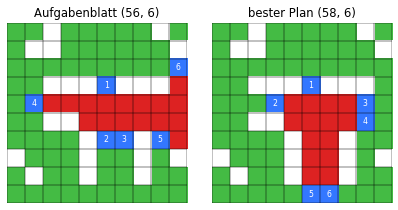

In [ ]:
def zeige_plan(plan):
    for stunde in range(1, len(plan) + 1):
        feld = plan[stunde - 1]
        if feld is None:
            print(f'Stunde {stunde}: nichts tun')
        else:
            print(f'Stunde {stunde}: Zeile {feld[0]}, Spalte {feld[1]} löschen')


zeige_plan(st_blatt['plan'])
verlauf_bester = spiele(blatt, st_blatt['plan'])
print('Probe mit spiele:', bewertung(verlauf_bester))
male(blatt, [verlauf_blatt[-1], verlauf_bester[-1]], ['Aufgabenblatt (56, 6)', 'bester Plan (58, 6)'], spalten=2)

Der Unterschied: Der Plan des Aufgabenblatts löscht in Stunde 2 und 3 unten in der Mitte, lässt das Feuer aber nach rechts bis an
den Rand laufen. Der beste Plan sperrt das Feuer früh links und rechts ein und lässt es nur nach unten durch die schmale Gasse
zwischen den Schneisen, wo zwei Löschungen am unteren Rand reichen.

## Alle Beispiele

Für jede Karte vergleichen wir den gierigen Plan mit dem besten und zählen die untersuchten Lagen. Bei `zwei_herde` und
`drei_herde` brennt es an mehreren Stellen gleichzeitig; dafür mussten wir nichts ändern, denn `feuer` ist von Anfang an eine Menge.

In [ ]:
DATEIEN = ['beispieldaten/aufgabenblatt.txt', 'eigene_testdaten/klein.txt',
           'eigene_testdaten/zwei_herde.txt', 'eigene_testdaten/drei_herde.txt']
karten = {}
beste = {}
print(f'{"Karte":16} {"Größe":>7} {"Herde":>5} {"Wald":>5} {"gierig":>9} {"bester":>9} {"Zustände":>9}')
for datei in DATEIEN:
    karte = lies_karte(datei)
    karten[datei] = karte
    wald, feuer = felder(karte)
    g = bewertung(spiele(karte, gierig(karte)))
    st = beste_loesung(karte)
    beste[datei] = st
    assert bewertung(spiele(karte, st['plan'])) == st['beste']      # Probe
    groesse = f'{len(karte)}x{len(karte[0])}'
    print(f'{datei.split("/")[1]:16} {groesse:>7} {len(feuer):>5} {len(wald):>5} {str(g):>9} {str(st["beste"]):>9} {st["zustaende"]:>9}')

Karte              Größe Herde  Wald    gierig    bester  Zustände
aufgabenblatt.txt   10x10     1    77   (58, 6)   (58, 6)       140
klein.txt            6x6     1    30   (11, 4)   (16, 4)       152
zwei_herde.txt     15x15     2   176 (110, 11)  (147, 5)     13409
drei_herde.txt     20x20     3   305 (196, 21) (245, 10)     11169


„Wald“ zählt die Waldfelder ohne die Brandherde. Gierig liegt bei den Zufallskarten weit hinter dem Optimum: Bei `drei_herde`
verliert es 49 Waldfelder mehr und braucht dafür 21 statt 10 Löschungen. Die Pläne für die beiden großen Karten:

eigene_testdaten/zwei_herde.txt
Stunde 1: Zeile 8, Spalte 13 löschen
Stunde 2: Zeile 10, Spalte 14 löschen
Stunde 3: Zeile 4, Spalte 3 löschen
Stunde 4: Zeile 4, Spalte 4 löschen
Stunde 5: Zeile 3, Spalte 6 löschen

eigene_testdaten/drei_herde.txt
Stunde 1: Zeile 6, Spalte 9 löschen
Stunde 2: Zeile 2, Spalte 4 löschen
Stunde 3: Zeile 9, Spalte 9 löschen
Stunde 4: Zeile 5, Spalte 5 löschen
Stunde 5: Zeile 11, Spalte 9 löschen
Stunde 6: Zeile 11, Spalte 4 löschen
Stunde 7: Zeile 5, Spalte 10 löschen
Stunde 8: Zeile 3, Spalte 13 löschen
Stunde 9: Zeile 1, Spalte 14 löschen
Stunde 10: Zeile 4, Spalte 14 löschen



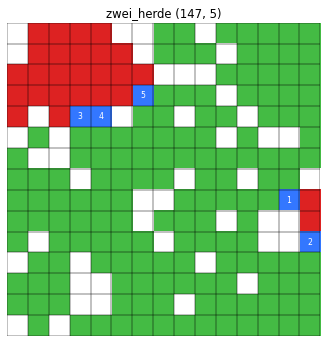

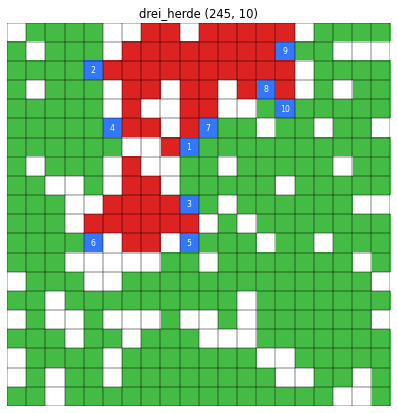

In [ ]:
for datei in DATEIEN[2:]:
    print(datei)
    zeige_plan(beste[datei]['plan'])
    print()
male(karten[DATEIEN[2]], [spiele(karten[DATEIEN[2]], beste[DATEIEN[2]]['plan'])[-1]], ['zwei_herde (147, 5)'], spalten=1, zoll=5)
male(karten[DATEIEN[3]], [spiele(karten[DATEIEN[3]], beste[DATEIEN[3]]['plan'])[-1]], ['drei_herde (245, 10)'], spalten=1, zoll=6)

**Wie groß darf die Karte sein?** Die Rechenzeit hängt weniger von der Größe als von der Form des Waldes ab. Viele Schneisen bremsen
das Feuer, die Front bleibt schmal und die Schranke greift. Auf großen freien Flächen wird die Front dagegen breit, es gibt in jeder
Stunde viele Möglichkeiten, und die Zahl der Lagen wächst sehr schnell (siehe „Für Neugierige“). Beim Feuerring aus den
Lösungshinweisen (20 × 16 Felder, nur Wald) braucht unsere Suche mehrere Millionen Lagen; das rechnen wir deshalb nicht im Notebook.

## Sheilas Frage: Lohnt es sich, Wald vorher nass zu machen?

**Kurz: Ja, manchmal.**

**Überlegung.** Löschen wir ein Feuerfeld gleich in der Stunde, in der es Feuer gefangen hat, kann es niemanden anstecken; es
wirkt wie ein Stück Brandschneise. Ein vorher gegossenes Waldfeld wirkt genauso, nur haben wir das Wasser **früher** abgeworfen.
Gießen heißt also: Arbeit vorziehen. Daraus folgt:

- Gießen ist nie schlechter, denn jeder Plan, der nur Feuer löscht, ist auch erlaubt, wenn man gießen darf.
- Gießen hilft, wenn mehrere Felder **gleichzeitig** gesperrt werden müssten, der Hubschrauber aber nur eines pro Stunde schafft,
  und es vorher Stunden gibt, in denen er nichts Wichtiges zu tun hat.
- Gießen hilft nicht, wenn die nötigen Sperren ohnehin nacheinander fällig werden, wie beim Aufgabenblatt.
- Nur Waldfelder, die über Wald mit dem Feuer verbunden sind, kommen in Frage (die Hinweise nennen das *Feuerlinien-Kriterium*);
  alles andere ist ohnehin sicher.

Wir zählen gegossene Felder wie die Hinweise als gelöscht, nicht als Wald. (Nach dem Wortlaut der Aufgabe sind sie nie „in Brand
geraten“; so gezählt wäre Gießen noch etwas attraktiver.)

Unsere Suche kann das schon: Mit `giessen=True` kommen alle Waldfelder aus `wald_am_feuer` als Kandidaten dazu. Die Schranke gilt
weiter, denn ein gegossenes Waldfeld zählt auch nicht mehr als Wald.

In [ ]:
for datei in DATEIEN[:2]:
    st_g = beste_loesung(karten[datei], giessen=True)
    print(f'{datei:32} nur Feuer {beste[datei]["beste"]}  mit Gießen {st_g["beste"]}  Zustände {st_g["zustaende"]}')

beispieldaten/aufgabenblatt.txt  nur Feuer (58, 6)  mit Gießen (58, 6)  Zustände 13124
eigene_testdaten/klein.txt       nur Feuer (16, 4)  mit Gießen (16, 4)  Zustände 1526


Beim Aufgabenblatt und bei der kleinen Karte bringt Gießen nichts. Die Suche wird aber viel aufwendiger, weil es viel mehr
Kandidaten gibt. Bei `zwei_herde` ändert sich das Ergebnis ebenfalls nicht; das haben wir beim Erstellen des Notebooks geprüft, die
Suche brauchte dafür rund 7,2 Millionen Lagen (statt 13 409 ohne Gießen). `drei_herde` ist mit Gießen zu groß für unsere Suche.

**Ein Feuerring.** Ganz anders, wenn das Feuer einen Wald von allen Seiten umschließt, wie in Abbildung 1 der Lösungshinweise.
Das Feuer frisst sich von außen Ring für Ring nach innen, an vielen Stellen gleichzeitig. Wir probieren quadratische Ringe
verschiedener Größe:

In [ ]:
def feuerring(hoehe, breite):
    """Karte: Rand aus Feuer, innen nur Wald."""
    karte = ['F' * breite]
    for z in range(hoehe - 2):
        karte.append('F' + '.' * (breite - 2) + 'F')
    karte.append('F' * breite)
    return karte


ringe = {}
print(f'{"Größe":>6} {"Wald":>5} {"nur Feuer":>10} {"Zustände":>9} {"mit Gießen":>11} {"Zustände":>9}')
for n in range(5, 12):
    karte = feuerring(n, n)
    a = beste_loesung(karte)
    g = beste_loesung(karte, giessen=True)
    ringe[n] = (a, g)
    print(f'{n:>4}x{n:<2} {(n - 2) ** 2:>4} {str(a["beste"]):>10} {a["zustaende"]:>9} {str(g["beste"]):>11} {g["zustaende"]:>9}')

 Größe  Wald  nur Feuer  Zustände  mit Gießen  Zustände
   5x5     9     (0, 0)         6      (0, 0)         7
   6x6    16     (0, 0)        10      (0, 0)        14
   7x7    25     (0, 0)        48      (0, 0)        87
   8x8    36     (0, 0)       140      (0, 0)       364
   9x9    49     (0, 0)       455      (1, 4)      1391
  10x10   64     (0, 0)      1415      (1, 4)      7052
  11x11   81     (1, 5)      3482      (1, 4)     27467


Beim Ring 9 × 9 rettet nur Gießen ein Waldfeld: Es wird von vier gegossenen Feldern umschlossen. Diese vier Felder würden fast
gleichzeitig Feuer fangen; nur mit Feuer-Löschen schafft der Hubschrauber das nicht.

Stunde 1: Zeile 2, Spalte 4 löschen
Stunde 2: Zeile 3, Spalte 3 löschen
Stunde 3: Zeile 3, Spalte 5 löschen
Stunde 4: Zeile 4, Spalte 4 löschen
Probe: (1, 4)


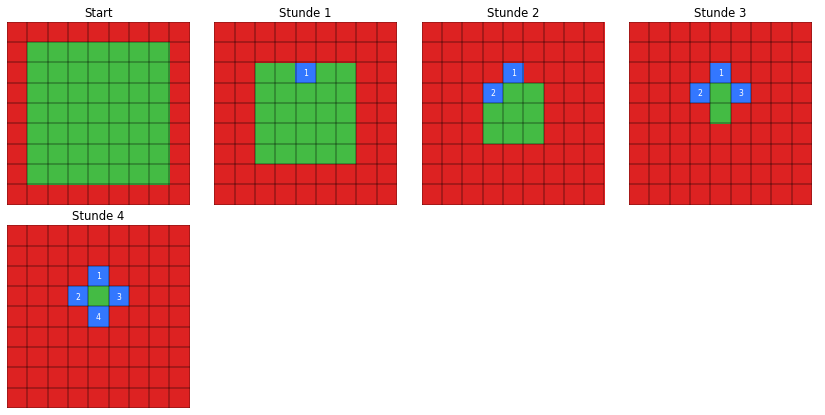

In [ ]:
ring9 = feuerring(9, 9)
plan9 = ringe[9][1]['plan']
zeige_plan(plan9)
verlauf9 = spiele(ring9, plan9, giessen=True)
print('Probe:', bewertung(verlauf9))
male(ring9, verlauf9, ['Start', 'Stunde 1', 'Stunde 2', 'Stunde 3', 'Stunde 4'])

Ab 11 × 11 kann man auch nur mit Feuer-Löschen ein Feld retten, gießend dann mit weniger Wasser. Beim Erstellen des Notebooks haben
wir größere Ringe gerechnet (dauert zu lange für hier): 12 × 12 wie 11 × 11; bei 13 × 13 rettet Gießen 2 Felder, bei 14 × 14 sogar 3,
nur mit Feuer-Löschen bleibt es bei 1. Je mehr Zeit bis zur Mitte, desto mehr kann man vorarbeiten.

**Zufallskarten.** Wie oft hilft Gießen auf „gewöhnlichen“ Karten? Wir erzeugen 100 Karten mit 7 × 7 Feldern, etwa 20 % Schneisen
und einem Brandherd, und vergleichen beide Optima.

In [ ]:
import random


def zufallskarte(zufall, groesse, anteil_schneisen):
    karte = []
    for z in range(groesse):
        zeile = ''
        for s in range(groesse):
            if zufall.random() < anteil_schneisen:
                zeile += '#'
            else:
                zeile += '.'
        karte.append(zeile)
    z = zufall.randrange(groesse)
    s = zufall.randrange(groesse)
    karte[z] = karte[z][:s] + 'F' + karte[z][s + 1:]
    return karte


zufall = random.Random(2014)
zufallskarten = []
mehr_wald = []
weniger_wasser = 0
for i in range(100):
    karte = zufallskarte(zufall, 7, 0.2)
    zufallskarten.append(karte)
    a = beste_loesung(karte)['beste']
    g = beste_loesung(karte, giessen=True)['beste']
    if g[0] > a[0]:
        mehr_wald.append((i, a, g))
    elif g != a:
        weniger_wasser += 1
print('Gießen rettet mehr Wald:', len(mehr_wald), 'von 100 Karten')
for eintrag in mehr_wald:
    print('  Karte', eintrag[0], ' nur Feuer', eintrag[1], ' mit Gießen', eintrag[2])
print('Gleich viel Wald, aber weniger Wasser:', weniger_wasser)

Gießen rettet mehr Wald: 4 von 100 Karten
  Karte 0  nur Feuer (18, 5)  mit Gießen (21, 4)
  Karte 6  nur Feuer (26, 7)  mit Gießen (31, 4)
  Karte 59  nur Feuer (29, 3)  mit Gießen (30, 3)
  Karte 92  nur Feuer (23, 4)  mit Gießen (24, 4)
Gleich viel Wald, aber weniger Wasser: 0


Bei 4 von 100 Karten rettet Gießen mehr Wald, bei den übrigen 96 ist das Ergebnis genau gleich. Am deutlichsten ist Karte 6: 5
Waldfelder mehr und dazu weniger Wasser. So sehen die beiden besten Pläne aus:

Stunde 1: Zeile 2, Spalte 4 löschen
Stunde 2: Zeile 3, Spalte 5 löschen
Stunde 3: Zeile 2, Spalte 3 löschen
Stunde 4: Zeile 4, Spalte 6 löschen


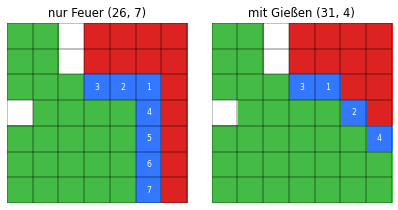

In [ ]:
karte6 = zufallskarten[6]
plan6_feuer = beste_loesung(karte6)['plan']
plan6_giessen = beste_loesung(karte6, giessen=True)['plan']
zeige_plan(plan6_giessen)
male(karte6, [spiele(karte6, plan6_feuer)[-1], spiele(karte6, plan6_giessen, giessen=True)[-1]],
     ['nur Feuer ' + str(mehr_wald[1][1]), 'mit Gießen ' + str(mehr_wald[1][2])], spalten=2)

Das Feuer beginnt oben rechts. Mit Gießen baut der Hubschrauber in vier Stunden eine schräge Sperre aus den Feldern (2, 3), (2, 4),
(3, 5) und (4, 6), *bevor* das Feuer dort ankommt. Nur mit Feuer-Löschen kann er erst löschen, was schon brennt; er läuft dem Feuer
hinterher und muss eine lange Wand an Spalte 5 hinunter löschen. Ergebnis: 5 Waldfelder weniger und 3 Löschungen mehr.

**Der Feuerring der Lösungshinweise.** Die Hinweise schreiben zu Abbildung 1 (Ring 20 × 16): „Löscht man jedoch nur Feuer-Felder,
kann man kein einziges Wald-Feld retten.“ Das stimmt nicht. Schon beim Ring 11 × 11 oben rettet man ein Feld, und für den Ring
der Hinweise hat unsere Suche beim Erstellen des Notebooks (in 3 781 680 Lagen) sogar einen Plan mit 3 Waldfeldern gefunden.
Diesen Plan prüfen wir hier mit `spiele`:

nur Feuer löschen: (3, 9)


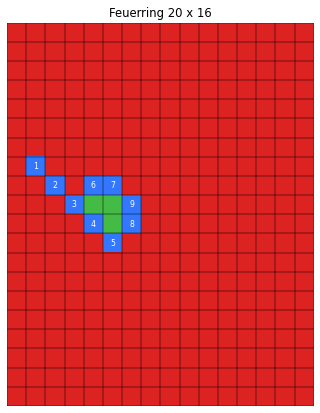

In [ ]:
feuerring_hinweise = lies_karte('beispieldaten/feuerring.txt')
plan_ring = [(7, 1), (8, 2), (9, 3), (10, 4), (11, 5), (8, 4), (8, 5), (10, 6), (9, 6)]
verlauf_ring = spiele(feuerring_hinweise, plan_ring)
print('nur Feuer löschen:', bewertung(verlauf_ring))
male(feuerring_hinweise, [verlauf_ring[-1]], ['Feuerring 20 x 16'], spalten=1, zoll=6)

Der Hubschrauber löscht in den ersten fünf Stunden eine schräge Linie, jeweils das Feld, das gerade Feuer gefangen hat. Hinter
dieser Linie bleibt eine kleine Tasche, die er mit vier weiteren Löschungen schließt, bevor das Feuer hineinkommt. Für quadratische
Ringe bis 10 × 10 stimmt die Aussage der Hinweise (siehe Tabelle oben), für größere nicht.

Und mit Gießen? Dafür ist unsere Suche viel zu langsam. MiniZinc (Chuffed, siehe „Zum Schluss“) hat beim Erstellen des Notebooks in
5 Minuten einen Plan gefunden, der **4** Waldfelder rettet, ohne beweisen zu können, dass es nicht besser geht. Wir prüfen ihn und
probieren dazu aus, was passiert, wenn der Hubschrauber in Stunde 1 nichts tut:

In [ ]:
plan_ring_giessen = [(9, 2), (8, 12), (7, 11), (9, 11), (10, 10), (7, 10), (10, 9), (8, 9), (9, 8)]
verlauf_ring_g = spiele(feuerring_hinweise, plan_ring_giessen, giessen=True)
print('mit Gießen:', bewertung(verlauf_ring_g))
ohne_stunde1 = [None] + plan_ring_giessen[1:]
print('ohne das Wasser in Stunde 1:', bewertung(spiele(feuerring_hinweise, ohne_stunde1, giessen=True)))
for zeile in als_text(feuerring_hinweise, *verlauf_ring_g[-1])[6:12]:
    print(zeile)

mit Gießen: (4, 9)
ohne das Wasser in Stunde 1: (0, 8)
FFFFFFFFFFFFFFFF
FFFFFFFFFF63FFFF
FFFFFFFFF8..2FFF
FF1FFFFF9..4FFFF
FFFFFFFFF75FFFFF
FFFFFFFFFFFFFFFF


(Gezeigt sind die Zeilen 6 bis 11 der Endlage.) Das erste Wasser fällt weit links auf das Feld (9, 2), das sieht nutzlos aus.
Ohne es geht aber alles verloren! Hinter dem nassen Feld kommt das Feuer in Zeile 9 jeweils eine Stunde später an, Feld für Feld
nach rechts. Die Löschungen der Stunden 2 bis 8 umschließen die Tasche von oben, rechts und unten. Das letzte Loch ist das Feld
(9, 8), und dorthin kommt das Feuer über Zeile 9 von links. Ohne das nasse Feld (9, 2) brennt es dort eine Stunde zu früh; mit ihm
kann der Hubschrauber das Loch in Stunde 9 noch schließen. Gießen kann das Feuer also auch **bremsen**.

**Antwort an Sheila:** Ja, es kann mehr Wald gerettet werden. Gießen ist nie schlechter als nur Feuer zu löschen und hilft genau
dann, wenn man Sperren *vorbereiten* muss, weil später mehrere Felder in derselben Stunde gelöscht werden müssten. Auf Karten mit
vielen Schneisen kommt das selten vor (oben bei 4 von 100 Zufallskarten), bei großen freien Waldflächen, die von
mehreren Seiten brennen, oft. Der Preis: Die Suche muss viel mehr Kandidaten prüfen.

## Für Neugierige

### Alle besten Pläne für das Aufgabenblatt

Die Lösungshinweise zeigen fünf optimale Endlagen (Abbildung 3d bis 3h). Gibt es wirklich nur fünf? Wir zählen alle Pläne mit
`(58, 6)`. Dazu ändern wir die Suche: kein Merken (sonst gingen gleich gute Wege verloren), abbrechen nur, wenn es *sicher*
schlechter wird, und am Ende jeden Plan mit genau `(58, 6)` sammeln.

5 optimale Pläne
[(3, 5), (4, 3), (4, 8), (5, 8), (9, 5), (9, 6)]
[(3, 5), (4, 7), (4, 2), (5, 8), (9, 5), (9, 6)]
[(3, 5), (4, 7), (5, 7), (4, 1), (9, 5), (9, 6)]
[(4, 4), (2, 5), (4, 8), (5, 8), (9, 5), (9, 6)]
[(4, 6), (2, 5), (5, 7), (4, 1), (9, 5), (9, 6)]


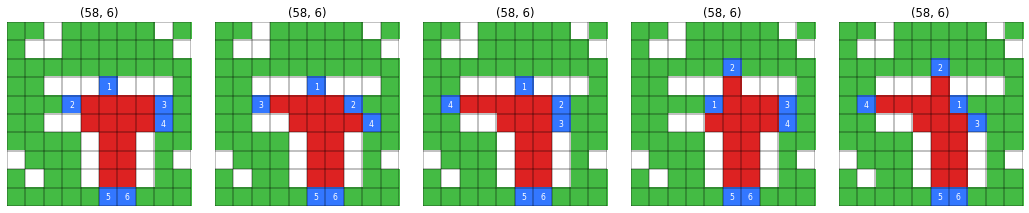

In [ ]:
def alle_besten(wald, feuer, anzahl_geloescht, plan, ziel, gefunden):
    front = feuerfront(wald, feuer)
    if len(front) == 0:
        if (len(wald), anzahl_geloescht) == ziel:
            gefunden.append(plan)
        return
    if anzahl_geloescht >= ziel[1]:                  # noch ein Feld mehr wäre zu viel Wasser
        return
    bedroht = {}
    for f in front:
        for n in nachbarn(f):
            if n in wald:
                bedroht[n] = bedroht.get(n, 0) + 1
    rettet_max = 0
    for f in front:
        r = 0
        for n in nachbarn(f):
            if n in wald and bedroht[n] == 1:
                r += 1
        rettet_max = max(rettet_max, r)
    if len(wald) - len(bedroht) + rettet_max < ziel[0]:
        return
    for feld in sorted(front) + [None]:
        if feld is None:
            wald2, feuer2 = feuer_zug(wald, front)
            alle_besten(wald2, feuer2, anzahl_geloescht, plan + [None], ziel, gefunden)
        else:
            wald2, feuer2 = feuer_zug(wald - {feld}, front - {feld})
            alle_besten(wald2, feuer2, anzahl_geloescht + 1, plan + [feld], ziel, gefunden)


wald, feuer = felder(blatt)
wald, feuer = feuer_zug(wald, feuer)
optimale = []
alle_besten(wald, feuer, 0, [], (58, 6), optimale)
print(len(optimale), 'optimale Pläne')
for p in optimale:
    print(p)
male(blatt, [spiele(blatt, p)[-1] for p in optimale], ['(58, 6)'] * len(optimale), spalten=5)

Es sind genau fünf, und es sind dieselben wie in den Hinweisen, sogar mit derselben Reihenfolge der Löschungen. Allen gemeinsam ist
das Ende: In Stunde 5 und 6 werden die beiden Felder am unteren Rand gelöscht.

### Wie schnell wächst die Suche?

Die Zahl der untersuchten Lagen für die Feuerringe (nur Feuer löschen) aus der Tabelle oben, ergänzt um die größeren Ringe, die wir
außerhalb des Notebooks gerechnet haben:

| Ring | 9 × 9 | 10 × 10 | 11 × 11 | 12 × 12 | 13 × 13 | 14 × 14 | 20 × 16 (Hinweise) |
|---|---|---|---|---|---|---|---|
| untersuchte Lagen | 455 | 1 415 | 3 482 | 11 530 | 30 778 | 89 790 | 3 781 680 |

Pro Zeile und Spalte mehr wächst die Zahl etwa um den Faktor 3, also **exponentiell**. Das ist typisch für eine vollständige Suche
in einem Spielbaum; Schranke und Merken verschieben die Grenze, heben sie aber nicht auf. Ein Verfahren, das für jede Karte schnell
den besten Plan findet, ist nicht bekannt (verwandte Probleme, etwa das *Firefighter-Problem* auf Graphen, sind NP-schwer). Für große
freie Flächen bleiben daher nur Heuristiken wie unser gieriges Verfahren; die Hinweise beschreiben noch weitere (zufällige Pläne
simulieren, „Gefahr reduzieren“).

Wie stark die Form zählt, zeigen auch Zufallskarten mit 20 × 20 Feldern, etwa 25 % Schneisen und drei Brandherden. Von zehn solchen
Karten (eine davon ist `drei_herde`) war die Suche beim Erstellen des Notebooks bei vier nach 1 181 bis 63 905 Lagen fertig, bei den
anderen sechs auch nach 300 000 Lagen nicht.

## Zum Schluss: Buschfeuer mit MiniZinc

Lässt sich der beste Löschplan auch mit MiniZinc finden? Das Spiel läuft Stunde für Stunde ab. Wir legen deshalb eine Höchstzahl `T`
von Stunden fest und beschreiben jede Stunde mit Bool-Variablen, ein Feld pro Eintrag eines Arrays mit drei Indizes
(Stunde, Zeile, Spalte):

- `brand[t, i, j]`: Das Feld hat nach dem Feuer-Zug `t` gebrannt (`t = 0` ist der Start).
- `wasser[t, i, j]`: Im Lösch-Zug `t` wird dieses Feld gelöscht.
- `nass[t, i, j]`: Das Feld ist nach dem Lösch-Zug `t` gelöscht.

Die Spielregeln werden zu Gleichungen zwischen Stunde `t − 1` und Stunde `t`. Neu gegenüber den Arbeitsblättern:

- `exists(...)(...)` ist das Gegenstück zu `forall`: wahr, wenn die Bedingung für **mindestens einen** Wert gilt. Wir nutzen es für
  die vier Nachbarn; das `where` sortiert Nachbarn außerhalb der Karte aus.
- Ein `predicate` ist eine Abkürzung für eine Bedingung mit Parametern, ähnlich einer Funktion in Python. `feuer_daneben(t, i, j)`
  fragt, ob nach dem Lösch-Zug `t` ein Nachbar von `(i, j)` brennt, der nicht gelöscht ist.
- `a -> b` heißt „wenn a, dann b“.
- In Summen zählt `true` als 1. Wir maximieren `1000 * W − G`: zuerst möglichst viel Wald, bei gleichem Wald möglichst wenig Wasser.

```minizinc
int: H;                                       % Zeilen
int: B;                                       % Spalten
int: T;                                       % höchstens T Stunden (Lösch-Züge)
bool: giessen;                                % dürfen auch Waldfelder gelöscht werden?
array[1..H, 1..B] of 0..2: karte;             % 0 Schneise, 1 Wald, 2 Feuer

array[0..T, 1..H, 1..B] of var bool: brand;   % Feld hat nach dem Feuer-Zug t gebrannt (t = 0: Start)
array[1..T, 1..H, 1..B] of var bool: wasser;  % Feld wird im Lösch-Zug t gelöscht
array[0..T, 1..H, 1..B] of var bool: nass;    % Feld ist nach dem Lösch-Zug t gelöscht

% brennt nach dem Lösch-Zug t ein Nachbar von (i, j), der noch nicht gelöscht ist?
predicate feuer_daneben(int: t, int: i, int: j) =
    exists(di in -1..1, dj in -1..1 where abs(di) + abs(dj) = 1 /\ i + di in 1..H /\ j + dj in 1..B)
          (brand[t, i + di, j + dj] /\ not nass[t, i + di, j + dj]);

constraint forall(i in 1..H, j in 1..B)(brand[0, i, j] = (karte[i, j] = 2) /\ not nass[0, i, j]);

% Lösch-Zug t: höchstens ein Feld; es brennt (oder ist Wald, wenn gegossen werden darf)
constraint forall(t in 1..T)(sum(i in 1..H, j in 1..B)(wasser[t, i, j]) <= 1);
constraint forall(t in 1..T, i in 1..H, j in 1..B)(
    wasser[t, i, j] -> (karte[i, j] > 0 /\ not nass[t - 1, i, j] /\ (giessen \/ brand[t, i, j])));
constraint forall(t in 1..T, i in 1..H, j in 1..B)(nass[t, i, j] = (nass[t - 1, i, j] \/ wasser[t, i, j]));

% Feuer-Zug t: ein trockenes Waldfeld fängt Feuer, wenn daneben ein Feld brennt
constraint forall(t in 1..T, i in 1..H, j in 1..B)(
    brand[t, i, j] = (brand[t - 1, i, j] \/
                      (karte[i, j] = 1 /\ not nass[t - 1, i, j] /\ feuer_daneben(t - 1, i, j))));

% nach T Stunden ist das Feuer aus: kein übriges Waldfeld hat noch Feuer neben sich
constraint forall(i in 1..H, j in 1..B where karte[i, j] = 1)(
    (not brand[T, i, j] /\ not nass[T, i, j]) -> not feuer_daneben(T, i, j));

var int: W = sum(i in 1..H, j in 1..B where karte[i, j] = 1)(not brand[T, i, j] /\ not nass[T, i, j]);
var int: G = sum(t in 1..T, i in 1..H, j in 1..B)(wasser[t, i, j]);
solve maximize 1000 * W - G;

output ["(W, G) = (\(W), \(G))\n"] ++
       ["Stunde \(t): Zeile \(i - 1), Spalte \(j - 1)\n" | t in 1..T, i in 1..H, j in 1..B where fix(wasser[t, i, j])];
```

Die Datendatei schreibt `als_dzn`. Schneisen werden zu 0, Wald zu 1, Feuer zu 2. **Wie groß muss T sein?** Mindestens so groß wie die
Dauer des besten Einsatzes, sonst verbietet die letzte Bedingung („nach T Stunden ist das Feuer aus“) den besten Plan. Wir nehmen
die Länge des besten Python-Plans plus 2. Größeres T ist erlaubt, macht die Rechnung aber langsamer, weil jede Stunde neue Variablen
bringt.

In [ ]:
def als_dzn(karte, T, giessen=False):
    code = {'#': '0', '.': '1', 'F': '2'}
    zeilen = []
    for zeile in karte:
        werte = []
        for zeichen in zeile:
            werte.append(code[zeichen])
        zeilen.append('| ' + ', '.join(werte))
    text = f'H = {len(karte)};\nB = {len(karte[0])};\nT = {T};\ngiessen = {str(giessen).lower()};\n'
    return text + 'karte = [' + '\n         '.join(zeilen) + ' |];\n'


print(als_dzn(blatt, len(st_blatt['plan']) + 2))

H = 10;
B = 10;
T = 8;
giessen = false;
karte = [| 1, 1, 0, 1, 1, 1, 1, 1, 0, 1
         | 1, 0, 0, 1, 1, 1, 1, 1, 1, 0
         | 1, 1, 1, 1, 1, 1, 1, 1, 1, 1
         | 1, 1, 0, 0, 0, 1, 0, 0, 0, 1
         | 1, 1, 1, 1, 1, 2, 1, 1, 1, 1
         | 1, 1, 0, 0, 1, 1, 1, 1, 1, 1
         | 1, 1, 1, 1, 0, 1, 1, 0, 1, 1
         | 0, 1, 1, 1, 0, 1, 1, 0, 1, 0
         | 1, 0, 1, 1, 0, 1, 1, 0, 1, 1
         | 1, 1, 1, 1, 1, 1, 1, 1, 1, 1 |];



**Ausgabe von Chuffed für das Aufgabenblatt (T = 8):**

**Ausgabe:**

```
(W, G) = (58, 6)
Stunde 1: Zeile 3, Spalte 5
Stunde 2: Zeile 4, Spalte 7
Stunde 3: Zeile 5, Spalte 7
Stunde 4: Zeile 4, Spalte 1
Stunde 5: Zeile 9, Spalte 5
Stunde 6: Zeile 9, Spalte 6
----------
==========
```

**für `drei_herde` (T = 12):**

**Ausgabe:**

```
(W, G) = (245, 10)
Stunde 1: Zeile 6, Spalte 9
Stunde 2: Zeile 2, Spalte 4
Stunde 3: Zeile 9, Spalte 9
Stunde 4: Zeile 5, Spalte 5
Stunde 5: Zeile 11, Spalte 9
Stunde 6: Zeile 11, Spalte 4
Stunde 7: Zeile 5, Spalte 10
Stunde 8: Zeile 3, Spalte 13
Stunde 9: Zeile 3, Spalte 14
Stunde 10: Zeile 1, Spalte 15
----------
==========
```

**für den Ring 9 × 9 mit `giessen = true` (T = 6):**

**Ausgabe:**

```
(W, G) = (1, 4)
Stunde 1: Zeile 2, Spalte 4
Stunde 2: Zeile 3, Spalte 5
Stunde 3: Zeile 3, Spalte 3
Stunde 4: Zeile 4, Spalte 4
----------
==========
```

Beim Erstellen dieses Notebooks haben wir alle Beispiele so gerechnet und jeden Plan von MiniZinc mit `spiele` geprüft:
- **Nur Feuer löschen:** Für das Aufgabenblatt, `klein`, `zwei_herde` und `drei_herde` findet MiniZinc dieselbe Bewertung wie unsere
  Suche. Die Pläne sind teils andere: Beim Aufgabenblatt ist es der Plan aus Abbildung 3f der Hinweise, bei `drei_herde` sind die
  letzten beiden Löschungen anders. Chuffed braucht höchstens etwa 6 Sekunden (`drei_herde`), CP-SAT bis etwa 16 Sekunden; das
  Aufgabenblatt schaffen auch Gecode und HiGHS in 2 bis 3 Sekunden.
- **Der Feuerring der Hinweise** (T = 12): Chuffed beweist in knapp 5 Minuten, dass (3, 9) das Beste ist, unabhängig von unserem
  Programm. CP-SAT findet in 5 Minuten nicht einmal eine Lösung, mit und ohne Gießen.
- **Mit Gießen:** Aufgabenblatt und Ring 9 × 9 löst Chuffed in etwa einer Sekunde, `zwei_herde` in etwa 14 Sekunden mit (147, 5);
  unsere Suche brauchte dafür 7,2 Millionen Lagen. CP-SAT findet für `zwei_herde` mit Gießen in 5 Minuten keine Lösung. Bei `drei_herde` mit
  Gießen findet Chuffed in 5 Minuten nur einen Plan mit 208 Waldfeldern, schlechter als die 245 ohne Gießen; ob Gießen dort hilft,
  bleibt offen. Beim Feuerring mit Gießen findet Chuffed (T = 12) in 5 Minuten den Plan mit 4 Waldfeldern von oben, kann aber nicht
  beweisen, dass er optimal ist.
- **T zählt:** Beim Aufgabenblatt mit T = 15 statt 8 braucht Chuffed etwa 3 Sekunden, mit T = 25 etwa 6 und mit T = 40 etwa 20
  Sekunden. Gecode findet mit T = 15 in 3 Minuten nicht einmal das Optimum.

Wichtig: MiniZinc beweist nur, dass es keinen besseren Plan gibt, mit dem das Feuer nach höchstens T Stunden aus ist. Unsere
Python-Suche hat diese Grenze nicht.

**Fazit:** Für diese Aufgabe ist MiniZinc eine gute Ergänzung. Das Modell ist kurz und liest sich fast wie die Spielregeln. Bei
Sheilas Frage, wo unsere Suche an der Menge der Kandidaten erstickt, ist Chuffed deutlich schneller. Dafür muss man T passend wählen,
und bei großen freien Flächen stößt auch MiniZinc an seine Grenzen.